# Protein length

## 1. Data acquisition

ClinVar GRCh38 release July 20, 2026 supplies labels and population annotations. Reviewed human UniProt sequences were retrieved November 9, 2026; the exact response is checksum-pinned below. Each run verifies raw input bytes before processing. These are observational benchmark analyses, not clinical interpretation tools.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'am_hg38',
  'path': 'inputs/raw/AlphaMissense_hg38.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz',
  'sha256': '0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475',
  'bytes': 642961469},
 {'id': 'clinvar_vcf',
  'path': 'inputs/raw/clinvar_20260720.vcf.gz',
  'url': 'https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260720.vcf.gz',
  'sha256': 'ecedd212660c7e04c94ffdf8d516ec6881283ab501f4b7700b87e82c65e4551b',
  'bytes': 192806479},
 {'id': 'uniprot_human',
  'path': 'uniprot_reviewed_human_20261109.fasta.gz',
  'url': 'https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed%3Atrue%29&format=fasta&compressed=true',
  'sha256': '97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d',
  'bytes': 7505116}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_hg38.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475,642961469
1,clinvar_20260720.vcf.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260720.vcf.gz,ecedd212660c7e04c94ffdf8d516ec6881283ab501f4b7700b87e82c65e4551b,192806479
2,uniprot_reviewed_human_20261109.fasta.gz,https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed...,97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d,7505116


## 2. Raw processing

Keep single-nucleotide missense variants with an unambiguous pathogenic, likely pathogenic, benign or likely benign label and at least one-star review. Match the released AlphaMissense genomic key exactly, retain one row per protein substitution, and check the wild-type residue against the public canonical sequence. The 21-residue window must contain at least 11 standard amino acids.


In [3]:
_GCOLS = "RLPTAVGIF YCHQNKDEMW".replace(" ", "")
_GTRI = [
    ("S", [110, 145, 74, 58, 99, 124, 56, 142, 155, 144, 112, 89, 68, 46, 121, 65, 80, 135, 177]),
    ("R", [102, 103, 71, 112, 96, 125, 97, 97, 77, 180, 29, 43, 86, 26, 96, 54, 91, 101]),
    ("L", [98, 92, 96, 32, 138, 5, 22, 36, 198, 99, 113, 153, 107, 172, 138, 15, 61]),
    ("P", [38, 27, 68, 42, 95, 114, 110, 169, 77, 76, 91, 103, 108, 93, 87, 147]),
    ("T", [58, 69, 59, 89, 103, 92, 149, 47, 42, 65, 78, 85, 65, 81, 128]),
    ("A", [64, 60, 94, 113, 112, 195, 86, 91, 111, 106, 126, 107, 84, 148]),
    ("V", [109, 29, 50, 55, 192, 84, 96, 133, 97, 152, 121, 21, 88]),
    ("G", [135, 153, 147, 159, 98, 87, 80, 127, 94, 98, 127, 184]),
    ("I", [21, 33, 198, 94, 109, 149, 102, 168, 134, 10, 61]),
    ("F", [22, 205, 100, 116, 158, 102, 177, 140, 28, 40]),
    ("Y", [194, 83, 99, 143, 85, 160, 122, 36, 37]),
    ("C", [174, 154, 139, 202, 154, 170, 196, 215]),
    ("H", [24, 68, 32, 81, 40, 87, 115]),
    ("Q", [46, 53, 61, 29, 101, 130]),
    ("N", [94, 23, 42, 142, 174]),
    ("K", [101, 56, 95, 110]),
    ("D", [45, 160, 181]),
    ("E", [126, 152]),
    ("M", [67]),
]
GRANTHAM_PAIRS = {}
for _ri, (_raa, _vals) in enumerate(_GTRI):
    for _ci in range(_ri, len(_GCOLS)):
        GRANTHAM_PAIRS[(_raa, _GCOLS[_ci])] = _vals[_ci - _ri]
assert len(GRANTHAM_PAIRS) == 190, len(GRANTHAM_PAIRS)
def grantham(a, b):
    if a == b:
        return 0
    return GRANTHAM_PAIRS.get((a, b), GRANTHAM_PAIRS.get((b, a)))


In [4]:
# ClinVar annotations provide labels, review status and population observations.
keys={};counts=Counter()
with gzip.open(RAW/'clinvar_20260720.vcf.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');counts['VCF rows']+=1
        chrom,pos,vid,ref,alt=p[:5]
        if len(ref)!=1 or len(alt)!=1:continue
        info=dict(x.split('=',1) for x in p[7].split(';') if '=' in x)
        if info.get('CLNVC')!='single_nucleotide_variant' or 'missense_variant' not in info.get('MC',''):continue
        sig=info.get('CLNSIG','');rev=info.get('CLNREVSTAT','')
        if sig not in {'Pathogenic','Likely_pathogenic','Benign','Likely_benign'} or rev.startswith(('no_assertion','no_interpretation')):continue
        gi=info.get('GENEINFO','').split('|')[0].split(':')
        av=[float(info[k]) for k in ['AF_ESP','AF_EXAC','AF_TGP'] if k in info]
        keys[('chr'+chrom,int(pos),ref,alt)]={'variation_id':vid,'chrom':chrom,'pos':int(pos),'ref':ref,'alt':alt,'gene':gi[0],'entrez':gi[1] if len(gi)>1 else None,'label':int(sig in {'Pathogenic','Likely_pathogenic'}),'revstat':rev,'af_max':max(av) if av else np.nan}
counts['Eligible genomic keys']=len(keys)
# Stream exact genome-build/allele matches; duplicate protein substitutions retain
# the first occurrence in the released AlphaMissense file.
rows=[];seen=set()
with gzip.open(RAW/'AlphaMissense_hg38.tsv.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');counts['AM rows scanned']+=1
        key=(p[0],int(p[1]),p[2],p[3])
        if key not in keys:continue
        pk=(p[5],p[7])
        if pk in seen:counts['Duplicate protein substitutions']+=1;continue
        seen.add(pk)
        rows.append({**keys[key],'uniprot_id':p[5],'transcript_id':p[6],'protein_variant':p[7],'am':float(p[8])})
seqs={};name=None;buf=[]
with gzip.open(RAW/'uniprot_reviewed_human_20261109.fasta.gz','rt') as f:
    for line in f:
        line=line.strip()
        if line.startswith('>'):
            if name:seqs[name]=''.join(buf)
            name=line.split('|')[1];buf=[]
        else:buf.append(line)
    if name:seqs[name]=''.join(buf)
B62=substitution_matrices.load('BLOSUM62');AA=set('ACDEFGHIKLMNPQRSTVWY')
features=[]
for row in rows:
    m=re.fullmatch(r'([A-Z])(\d+)([A-Z])',row['protein_variant']);s=seqs.get(row['uniprot_id'])
    if not m or s is None:counts['Missing sequence or malformed substitution']+=1;continue
    wt,pos,alt=m[1],int(m[2]),m[3]
    if not 1<=pos<=len(s) or s[pos-1]!=wt:counts['Sequence mismatch']+=1;continue
    window=s[max(0,pos-11):min(len(s),pos+10)]
    if len(window)<11 or not set(window)<=AA or wt not in AA or alt not in AA:counts['Invalid local window']+=1;continue
    freq=np.array(list(Counter(window).values()))/len(window)
    features.append({**row,'wt_aa':wt,'alt_aa':alt,'aa_pos':pos,'protein_length':len(s),'term_dist':min(pos-1,len(s)-pos),'window_size':len(window),'entropy':round(float(-np.sum(freq*np.log2(freq))),6),'neg_blosum62':-float(B62[wt,alt]),'grantham':grantham(wt,alt)})
panel=pd.DataFrame(features);counts['Sequence-verified panel']=len(panel)
display(pd.Series(counts,name='count').to_frame());display(panel.drop(columns='am').head())


,count
VCF rows,4453798
Eligible genomic keys,179354
AM rows scanned,71697556
Duplicate protein substitutions,3084
Sequence mismatch,1864
Missing sequence or malformed substitution,63
Sequence-verified panel,164792


,variation_id,chrom,pos,ref,alt,gene,entrez,label,revstat,af_max,...,protein_variant,wt_aa,alt_aa,aa_pos,protein_length,term_dist,window_size,entropy,neg_blosum62,grantham
0,2205837,1,69134,A,G,OR4F5,79501,0,"criteria_provided,_single_submitter",NaN,...,E15G,E,G,15,305,14,21,2.910440,2.0,98
1,1648427,1,925969,C,T,SAMD11,148398,0,"criteria_provided,_single_submitter",0.00033,...,P10S,P,S,10,681,9,20,3.508695,1.0,74
2,1164676,1,930165,G,A,SAMD11,148398,0,"criteria_provided,_single_submitter",0.00280,...,R28Q,R,Q,28,681,27,21,3.535175,-1.0,43
3,1170208,1,930204,G,A,SAMD11,148398,0,"criteria_provided,_multiple_submitters,_no_conflicts",0.01098,...,R41Q,R,Q,41,681,40,21,3.427333,-1.0,43
4,789256,1,930248,G,A,SAMD11,148398,0,"criteria_provided,_multiple_submitters,_no_conflicts",0.00622,...,G56S,G,S,56,681,55,21,3.041626,-0.0,56


## 3. Axis and levels

Levels use input features only. Quartile boundaries, when used, are calculated on the sequence-verified cohort without labels. Exon distance includes transcript terminal exon edges. Low-support predefined levels are merged using variant counts only.


In [5]:
AXIS='Protein length'
FEATURE='protein_length'

cutpoints=panel[FEATURE].quantile([.25,.5,.75]).to_numpy()
assert len(np.unique(cutpoints))==3,'Quartiles coincide; inspect feature support.'
order=['L1: highest quartile','L2','L3','L4: lowest quartile']
panel['level']=pd.cut(panel[FEATURE],[-np.inf,*cutpoints,np.inf],labels=order[::-1]).astype(str)
df=panel.copy()
print('Input-only quartile boundaries:',cutpoints)

display(df.groupby('level')[FEATURE].agg(['size','min','median','max']).reindex(order))


Input-only quartile boundaries: [ 510.  917. 1834.]


,size,min,median,max
level,,,,
L1: highest quartile,41196,1835,2812.0,34350
L2,41156,918,1278.0,1834
L3,41221,511,681.0,917
L4: lowest quartile,41219,41,377.0,510


## 4. Model results and fixed references

AlphaMissense scores are the released GRCh38 predictions joined above. No training or fine-tuning occurs here. Higher scores mean greater pathogenicity for AlphaMissense, negative BLOSUM62, and Grantham distance. The reference matrices are defined in the code cells. All three predictors use exactly the same variants.


In [6]:
assert df[['am','neg_blosum62','grantham']].notna().all().all()
display(df[['variation_id','uniprot_id','protein_variant','label','am','neg_blosum62','grantham']].head())


,variation_id,uniprot_id,protein_variant,label,am,neg_blosum62,grantham
0,2205837,Q8NH21,E15G,0,0.0854,2.0,98
1,1648427,Q96NU1,P10S,0,0.9673,1.0,74
2,1164676,Q96NU1,R28Q,0,0.6624,-1.0,43
3,1170208,Q96NU1,R41Q,0,0.0866,-1.0,43
4,789256,Q96NU1,G56S,0,0.1004,-0.0,56


## 5. Curves and controls

Calculate per-level AUROC with 2,000 ordinary variant-bootstrap replicates, endpoint contrasts, review and composition strata, and gene-balanced endpoint contrasts where both labels and at least five variants occur at each endpoint. Variant-bootstrap intervals do not account for gene clustering; the separate gene summary makes that distinction visible.


,level,score,n,n_pathogenic,n_genes,AUROC,ci_low,ci_high
0,L1: highest quartile,am,41196,8680,579,0.955024,0.952635,0.957311
1,L1: highest quartile,neg_blosum62,41196,8680,579,0.694501,0.688357,0.700804
2,L1: highest quartile,grantham,41196,8680,579,0.701796,0.695116,0.708331
3,L2,am,41156,10013,2097,0.965905,0.964008,0.967609
4,L2,neg_blosum62,41156,10013,2097,0.712919,0.707585,0.718434
5,L2,grantham,41156,10013,2097,0.705536,0.699955,0.711356
6,L3,am,41221,12367,4258,0.970099,0.968576,0.971667
7,L3,neg_blosum62,41221,12367,4258,0.695519,0.689904,0.700850
8,L3,grantham,41221,12367,4258,0.687079,0.681251,0.692815
9,L4: lowest quartile,am,41219,13618,7713,0.971157,0.969725,0.972590


,score,delta_AUROC,ci_low,ci_high
0,am,-0.016133,-0.018991,-0.013387
1,neg_blosum62,0.002663,-0.005601,0.011082
2,grantham,0.022918,0.014420,0.031563


,control,score,n_first,n_last,delta_AUROC
0,review>=2,am,8791,8905,0.011890
1,review>=2,neg_blosum62,8791,8905,0.035237
2,review>=2,grantham,8791,8905,0.057770
3,entropy Q1,am,10527,9170,-0.019387
4,entropy Q1,neg_blosum62,10527,9170,-0.022692
5,entropy Q1,grantham,10527,9170,-0.005075
6,entropy Q2,am,10739,10466,-0.010648
7,entropy Q2,neg_blosum62,10739,10466,0.001387
8,entropy Q2,grantham,10739,10466,0.016136
9,entropy Q3,am,9842,10400,-0.014556


,score,eligible_genes,mean_delta,ci_low,ci_high
0,am,2,0.030172,0.000000,0.060345
1,grantham,2,0.283413,-0.016508,0.583333
2,neg_blosum62,2,0.098786,0.030906,0.166667


,n,pathogenic_fraction,genes,mean_entropy,mean_length,mean_grantham
level,,,,,,
L1: highest quartile,41196,0.210700,579,3.289223,3880.535829,74.822556
L2,41156,0.243294,2097,3.235445,1305.631281,72.244849
L3,41221,0.300017,4258,3.317439,690.835375,73.012057
L4: lowest quartile,41219,0.330382,7713,3.314311,359.865887,73.170916


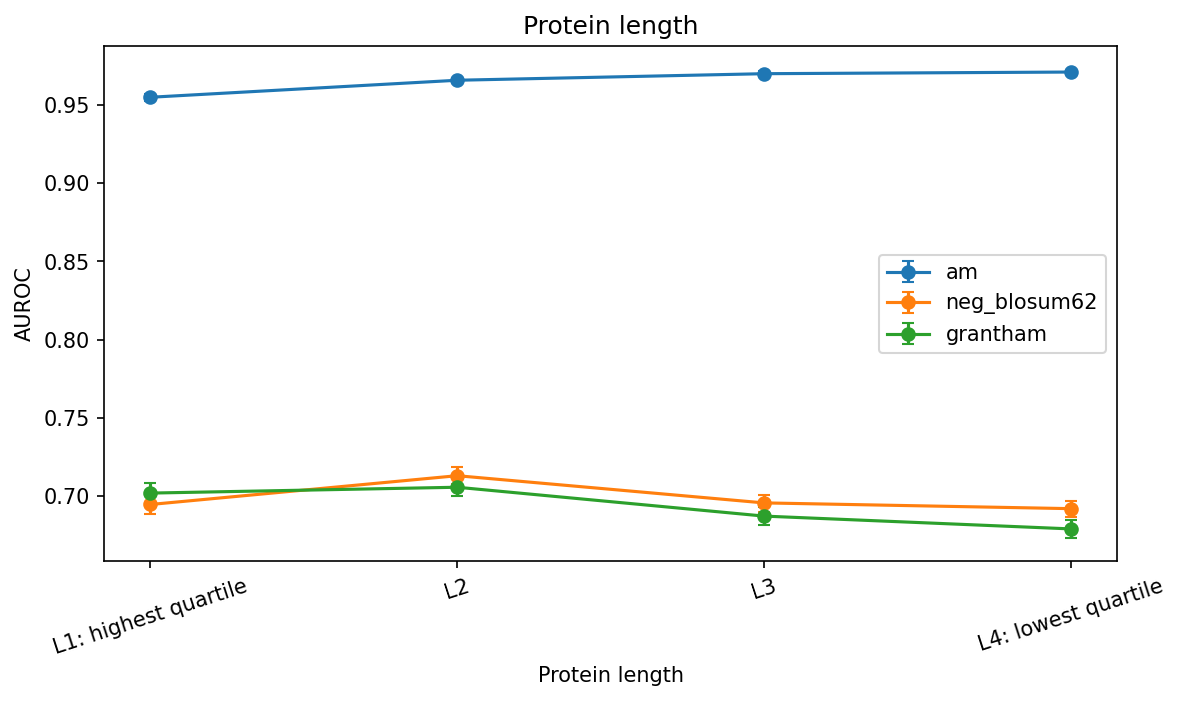

In [7]:
SCORES=['am','neg_blosum62','grantham'];B=2000;rng=np.random.default_rng(20260722)
def auc(y,s):
    y=np.asarray(y);s=np.asarray(s)
    return float(roc_auc_score(y,s)) if len(np.unique(y))==2 else np.nan
def auc_bootstrap(y,s,B=2000):
    # Multinomial sampling of (score,label) counts is exactly the ordinary
    # nonparametric variant bootstrap, including ties, without repeated sorting.
    y=np.asarray(y,dtype=int);s=np.asarray(s,dtype=float)
    values,inv=np.unique(s,return_inverse=True);m=len(values)
    counts=np.bincount(2*inv+y,minlength=2*m).reshape(m,2);n=counts.sum()
    probs=counts.ravel()/n;out=[]
    for start in range(0,B,32):
        w=rng.multinomial(n,probs,size=min(32,B-start)).reshape(-1,m,2)
        neg=w[:,:,0];pos=w[:,:,1];den=neg.sum(1)*pos.sum(1)
        numer=(pos*(np.cumsum(neg,axis=1)-.5*neg)).sum(1)
        out.extend(np.divide(numer,den,out=np.full(len(den),np.nan),where=den>0))
    return np.asarray(out)
rows=[];draws={}
for level in order:
    d=df.loc[df.level==level]
    for score in SCORES:
        bs=auc_bootstrap(d.label,d[score],B);draws[level,score]=bs;ci=np.nanquantile(bs,[.025,.975])
        rows.append({'level':level,'score':score,'n':len(d),'n_pathogenic':int(d.label.sum()),'n_genes':d.gene.nunique(),'AUROC':auc(d.label,d[score]),'ci_low':ci[0],'ci_high':ci[1]})
curves=pd.DataFrame(rows);deltas=[]
for score in SCORES:
    top=df[df.level==order[0]];bottom=df[df.level==order[-1]]
    bs=draws[order[0],score]-draws[order[-1],score];ci=np.nanquantile(bs,[.025,.975])
    deltas.append({'score':score,'delta_AUROC':auc(top.label,top[score])-auc(bottom.label,bottom[score]),'ci_low':ci[0],'ci_high':ci[1]})
deltas=pd.DataFrame(deltas)
# Controls retain the same level assignments: review quality, substitution
# severity, sequence complexity, protein length, and per-gene extreme support.
ctl=[]
star2={'criteria_provided,_multiple_submitters,_no_conflicts','reviewed_by_expert_panel','practice_guideline'}
strata=[('review>=2',df.revstat.isin(star2))]
for feature in ['entropy','protein_length','grantham']:
    bins=pd.qcut(df[feature],4,labels=False,duplicates='drop')
    strata.extend((feature+f' Q{q+1}',bins==q) for q in sorted(bins.dropna().unique()))
for name,mask in strata:
    d=df.loc[mask];a=d[d.level==order[0]];b=d[d.level==order[-1]]
    if min(len(a),len(b))<20 or min(a.label.nunique(),b.label.nunique())<2:continue
    for score in SCORES:ctl.append({'control':name,'score':score,'n_first':len(a),'n_last':len(b),'delta_AUROC':auc(a.label,a[score])-auc(b.label,b[score])})
controls=pd.DataFrame(ctl)
gene_rows=[]
for gene,d in df.groupby('gene'):
    a=d[d.level==order[0]];b=d[d.level==order[-1]]
    if min(len(a),len(b))<5 or min(a.label.nunique(),b.label.nunique())<2:continue
    for score in SCORES:gene_rows.append({'gene':gene,'score':score,'delta_AUROC':auc(a.label,a[score])-auc(b.label,b[score])})
within_gene=pd.DataFrame(gene_rows,columns=['gene','score','delta_AUROC'])
within_summary=[]
for score,d in within_gene.groupby('score'):
    x=d.delta_AUROC.to_numpy();bs=np.array([rng.choice(x,len(x),replace=True).mean() for _ in range(B)]);ci=np.quantile(bs,[.025,.975])
    within_summary.append({'score':score,'eligible_genes':len(x),'mean_delta':x.mean(),'ci_low':ci[0],'ci_high':ci[1]})
within_summary=pd.DataFrame(within_summary)
composition=df.groupby('level').agg(n=('label','size'),pathogenic_fraction=('label','mean'),genes=('gene','nunique'),mean_entropy=('entropy','mean'),mean_length=('protein_length','mean'),mean_grantham=('grantham','mean')).reindex(order)
display(curves);display(deltas);display(controls);display(within_summary);display(composition)
fig,ax=plt.subplots(figsize=(8,4.8))
for score,d in curves.groupby('score',sort=False):
    d=d.set_index('level').loc[order];y=d.AUROC.to_numpy();ax.errorbar(range(len(order)),y,yerr=[y-d.ci_low,d.ci_high-y],marker='o',capsize=3,label=score)
ax.set(xticks=range(len(order)),xticklabels=order,ylabel='AUROC',xlabel=AXIS,title=AXIS);ax.tick_params(axis='x',labelrotation=18);ax.legend();fig.tight_layout();show_figure(fig);plt.close(fig)
for name,table in [('variants',df),('curves',curves),('contrasts',deltas),('controls',controls),('within_gene',within_gene),('within_gene_summary',within_summary),('composition',composition.reset_index())]:table.to_csv(OUTPUT/f'{name}.csv',index=False)


## 6. Result and decision

The decision uses the newly calculated AlphaMissense contrast, its interval, fixed-reference direction, and the displayed controls. A positive endpoint contrast means performance falls from the first level to the last.


In [8]:
am=deltas.set_index('score').loc['am'];refs=deltas.loc[deltas.score!='am']
supported=bool(am.ci_low>0)
shared=bool((refs.delta_AUROC>0).any())
if not supported:
    decision='Do not retain this axis as a supported directional degradation claim: the AlphaMissense endpoint contrast is not positive with a confidence interval excluding zero.'
elif shared:
    decision='The marginal AlphaMissense degradation is supported, but at least one fixed reference degrades in the same direction. Treat this as a shared-difficulty axis; the composition and within-gene controls determine the strength of the interpretation.'
else:
    decision='The marginal AlphaMissense degradation is supported and neither fixed reference has a positive endpoint contrast. Retain it as a candidate model-sensitive axis, subject to the displayed composition and within-gene controls.'
if within_summary.empty:decision+=' No gene has enough labeled variants at both endpoints for the specified within-gene calculation; gene composition remains unresolved.'
display(Markdown(decision))
receipt={'axis':AXIS,'sources':source_receipts,'variants':len(df),'levels':order,'bootstrap_replicates':B,'bootstrap_unit':'variant; gene for within-gene summary','seed':20260722,'decision':decision,'host':platform.node(),'elapsed_seconds':time.time()-STARTED,'outputs':{p.name:sha256_file(p) for p in sorted(OUTPUT.glob('*.csv'))}}
(OUTPUT/'execution.json').write_text(json.dumps(receipt,indent=2)+'\n')


Do not retain this axis as a supported directional degradation claim: the AlphaMissense endpoint contrast is not positive with a confidence interval excluding zero.

2050